# 3. SMAA-TOPSIS — xếp hạng các phương án Pareto

Bước 3 của chuỗi **Demand → Multi-Objective Optimization v2 → TOPSIS**.

- **Đọc:** `Model Outputs/18-10-2027/pareto.parquet` (lần chạy 18/10): 35 phương án P01–P35, mỗi phương án có `f1`, `f2_gio`, `f3`.
- **Xếp hạng bằng SMAA-TOPSIS** (Okul, Gencer & Aydogan, 2014). **Không dùng trọng số cố định**, vì không biết trọng số thật của ban lãnh đạo. Thay vào đó rút ngẫu nhiên 100,000 bộ trọng số, mỗi bộ chạy 1 lần TOPSIS, rồi đếm mỗi phương án đứng hạng 1, 2, 3… bao nhiêu % số lần.
- **Ghi:** CSV và hình vào `Model Outputs/18-10-2027/TOPSIS/`, bản đọc được vào `Model Outputs/Mẹ/`.
- Bản cũ dùng 4 kịch bản trọng số cố định được lưu ở `TOPSIS_backup_4kichban.ipynb`.

In [21]:
# ===== SETUP =====
import pandas as pd                       # xử lý bảng
import numpy as np                        # tính toán
from pathlib import Path                  # ghép đường dẫn

SEED = 7                                  # seed của bộ sinh số ngẫu nhiên (bản gốc: 42)

OUT_IN = Path("../Model Outputs")
OUT = OUT_IN / "18-10-2027"               # kết quả lần chạy 18/10 (Multi-Objective Optimization v2)
TOP = OUT / f"TOPSIS - {SEED}"            # thư mục kết quả TOPSIS theo seed (CSV + hình)
FIG = TOP                                 # hình để chung thư mục TOPSIS
MOM = OUT_IN / "Mẹ" if SEED == 42 else TOP / "Mẹ"   # seed 42 -> ghi vào thư mục Mẹ; seed khác -> để riêng trong TOP, không ghi đè bản của Mẹ
TOP.mkdir(exist_ok=True)
MOM.mkdir(parents=True, exist_ok=True)

pareto = pd.read_parquet(OUT / "pareto.parquet")                         # tập Pareto
print(f"Seed: {SEED} | Thư mục kết quả: {TOP}")
print(f"Số phương án Pareto: {len(pareto)}")
print(pareto[["PhuongAn", "f1", "f2_gio", "f3", "SoKhoMo", "Nguon"]].head(10).round(2).to_string(index=False))

Seed: 7 | Thư mục kết quả: ..\Model Outputs\18-10-2027\TOPSIS - 7
Số phương án Pareto: 35
PhuongAn     f1  f2_gio      f3  SoKhoMo         Nguon
     P01 306.06    5.02 2780.86     35.0 payoff min f1
     P02 306.35    4.61 2718.40     37.0     AUGMECON2
     P03 306.67    4.61 2705.08     38.0     AUGMECON2
     P04 306.77    4.44 2707.69     37.0     AUGMECON2
     P05 306.82    4.56 2695.30     39.0     AUGMECON2
     P06 306.97    4.44 2697.15     37.0     AUGMECON2
     P07 307.80    4.28 2667.92     39.0     AUGMECON2
     P08 307.81    4.25 2664.27     39.0     AUGMECON2
     P09 308.19    4.25 2638.24     40.0     AUGMECON2
     P10 308.28    4.05 2630.43     39.0     AUGMECON2


## 3.1 Ma trận quyết định

Mỗi hàng là 1 phương án Pareto, 3 cột là 3 tiêu chí, cả 3 đều **càng nhỏ càng tốt**:
`f1` chi phí (tỷ IDR/năm), `f2_gio` thời gian giao trung bình (giờ/pallet), `f3` CO2 (tấn/năm).

In [22]:
# ===== 3.1 MA TRẬN QUYẾT ĐỊNH =====
TIEU_CHI = ["f1", "f2_gio", "f3"]                                        # chi phí, thời gian giao, CO2
mt = pareto.set_index("PhuongAn")[TIEU_CHI]
PA = mt.index.to_numpy()                                                 # mã phương án P01 ... P35
X = mt.to_numpy(dtype=float)                                             # 35 x 3
assert mt.notna().all().all() and (X > 0).all(), "Ma trận phải đủ số và dương"
print(f"Ma trận quyết định: {X.shape[0]} phương án x {X.shape[1]} tiêu chí")
print(mt.head(10).round(2).to_string())

Ma trận quyết định: 35 phương án x 3 tiêu chí
              f1  f2_gio       f3
PhuongAn                         
P01       306.06    5.02  2780.86
P02       306.35    4.61  2718.40
P03       306.67    4.61  2705.08
P04       306.77    4.44  2707.69
P05       306.82    4.56  2695.30
P06       306.97    4.44  2697.15
P07       307.80    4.28  2667.92
P08       307.81    4.25  2664.27
P09       308.19    4.25  2638.24
P10       308.28    4.05  2630.43


## 3.2 SMAA-TOPSIS (không có thông tin trọng số)

**Cách làm** (Okul et al., 2014, Hình 3):

1. Rút ngẫu nhiên một bộ trọng số (chi phí, thời gian, CO2), phân bố **đều trên toàn tam giác trọng số** (3 số không âm, cộng lại = 1). Cách rút là **"cắt thước"**: rút 2 số đều trong [0, 1], sắp xếp, 3 khúc của thước dài 1 là 3 trọng số.
2. Chạy TOPSIS cho 35 phương án:
   chuẩn hoá vector từng cột → nhân trọng số → điểm lý tưởng = nhỏ nhất mỗi cột, điểm tệ nhất = lớn nhất → khoảng cách Euclid d+ và d− → điểm C = d− / (d+ + d−). Hạng 1 = C lớn nhất.
3. Ghi thứ hạng của cả 35 phương án. Lặp lại N = 100,000 lần (Okul et al. dùng 10,000; ở 100,000 lần, sai số mỗi tỷ lệ % tối đa khoảng ±0.3 điểm %).

**Kết quả:**

- **Tỷ lệ đạt hạng r** (rank acceptability): số lần phương án đứng hạng r / N.
- **Tỷ lệ top 3** = tỷ lệ hạng 1 + hạng 2 + hạng 3.
- **Trọng số trung tâm**: trung bình các bộ trọng số ở những lần phương án đứng hạng 1, tức "người chọn phương án này thường ưu tiên kiểu gì". Để trống nếu phương án không bao giờ đứng hạng 1.

**Không tính độ tin cậy (confidence factor).** Trong bài của Okul et al., số liệu tiêu chí là ngẫu nhiên (trung bình ± độ lệch chuẩn). Ở đây `f1`, `f2_gio`, `f3` là số cố định do mô hình tính ra, nên độ tin cậy chỉ ra 0 hoặc 1 và không có ý nghĩa.

In [23]:
# ===== 3.2a HÀM TOPSIS + KIỂM TRA VỚI SCIKIT-CRITERIA =====
def topsis(X, W):
    # X: m phương án x 3 tiêu chí (đều min); W: n bộ trọng số x 3 -> điểm TOPSIS n x m
    R = X / np.sqrt((X ** 2).sum(axis=0))                                # (1) chuẩn hoá vector từng cột
    V = W[:, None, :] * R[None, :, :]                                    # (2) nhân trọng số -> n x m x 3
    tot = V.min(axis=1, keepdims=True)                                   # (3) điểm lý tưởng = nhỏ nhất mỗi cột
    xau = V.max(axis=1, keepdims=True)                                   #     điểm tệ nhất = lớn nhất mỗi cột
    d_tot = np.sqrt(((V - tot) ** 2).sum(axis=2))                        # (4) khoảng cách Euclid tới điểm lý tưởng (d+)
    d_xau = np.sqrt(((V - xau) ** 2).sum(axis=2))                        #     tới điểm tệ nhất (d-)
    return d_xau / (d_tot + d_xau)                                       # (5) C = d- / (d+ + d-)

# --- Kiểm tra: trọng số 1/3 mỗi tiêu chí, hàm numpy phải ra đúng điểm của scikit-criteria (TOPSIS + VectorScaler) ---
import warnings
import skcriteria as skc
from skcriteria.agg.topsis import TOPSIS
from skcriteria.preprocessing.scalers import VectorScaler
from skcriteria.pipelines import mkpipe

w_deu = np.array([1 / 3, 1 / 3, 1 / 3])
dm = skc.mkdm(X, [min, min, min], weights=w_deu, alternatives=list(PA), criteria=TIEU_CHI)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                                      # skcriteria nhắc về tiêu chí min; TOPSIS gốc xử lý bằng điểm lý tưởng = min
    kq = mkpipe(VectorScaler(target="matrix"), TOPSIS()).evaluate(dm)
kiem_tra = pd.DataFrame({"PhuongAn": PA, "C_numpy": topsis(X, w_deu[None, :])[0], "C_skcriteria": kq.e_.similarity})
assert np.allclose(kiem_tra["C_numpy"], kiem_tra["C_skcriteria"]), "Hàm numpy khác scikit-criteria"
print("Kiểm tra hàm numpy = scikit-criteria (trọng số 1/3): OK")
print(kiem_tra.head(10).round(4).to_string(index=False))

Kiểm tra hàm numpy = scikit-criteria (trọng số 1/3): OK
PhuongAn  C_numpy  C_skcriteria
     P01   0.2353        0.2353
     P02   0.3218        0.3218
     P03   0.3230        0.3230
     P04   0.3772        0.3772
     P05   0.3386        0.3386
     P06   0.3779        0.3779
     P07   0.4416        0.4416
     P08   0.4539        0.4539
     P09   0.4566        0.4566
     P10   0.5380        0.5380


In [24]:
# ===== 3.2b RÚT 100,000 BỘ TRỌNG SỐ + CHẠY SMAA-TOPSIS =====
def rut_trong_so(n, rng):
    # "Cắt thước": 2 điểm cắt đều trong [0,1], sắp xếp -> 3 khúc = 3 trọng số, phân bố đều trên tam giác
    cat = np.sort(rng.random((n, 2)), axis=1)
    return np.column_stack([cat[:, 0], cat[:, 1] - cat[:, 0], 1 - cat[:, 1]])

def smaa(X, W):
    # Trả về HANG (n x m): hạng của mỗi phương án ở mỗi vòng; 1 = tốt nhất
    thu_tu = np.argsort(-topsis(X, W), axis=1)                           # phương án xếp từ điểm cao xuống thấp
    hang = np.empty_like(thu_tu)
    hang[np.arange(len(W))[:, None], thu_tu] = np.arange(1, X.shape[0] + 1)
    return hang

N = 100_000
W = rut_trong_so(N, np.random.default_rng(SEED))                         # seed cố định (đặt ở SETUP)
assert np.allclose(W.sum(axis=1), 1) and (W >= 0).all(), "Mỗi bộ trọng số phải >= 0 và cộng lại = 1"
HANG = smaa(X, W)
m = len(PA)

# --- Kiểm tra từng vòng: 10 vòng đầu, trọng số và phương án hạng 1 ---
vong = pd.DataFrame(W, columns=["W_ChiPhi", "W_ThoiGian", "W_CO2"])
vong["Hang1"] = PA[HANG.argmin(axis=1)]
print("10 vòng đầu: trọng số rút được và phương án hạng 1")
print(vong.head(10).round(3).to_string())

# --- (a) Tỷ lệ đạt hạng r: ma trận 35 phương án x 35 hạng (%) ---
day_du = pd.DataFrame(np.stack([np.bincount(HANG[:, i], minlength=m + 1)[1:] for i in range(m)]) / N * 100,
                      index=pd.Index(PA, name="PhuongAn"), columns=[f"Hang{r}_%" for r in range(1, m + 1)])
assert np.allclose(day_du.sum(axis=0), 100) and np.allclose(day_du.sum(axis=1), 100), "Mỗi hàng và mỗi cột phải cộng = 100%"

# --- (b) Bảng tóm tắt: hạng 1-3 và top 3 ---
chap_nhan = (pareto[["PhuongAn", "f1", "f2_gio", "f3", "SoKhoMo"]].set_index("PhuongAn")
             .join(day_du[["Hang1_%", "Hang2_%", "Hang3_%"]]))
chap_nhan["Top3_%"] = chap_nhan[["Hang1_%", "Hang2_%", "Hang3_%"]].sum(axis=1)
chap_nhan = chap_nhan.sort_values(["Hang1_%", "Top3_%"], ascending=False).reset_index()
print("\nTỷ lệ đạt hạng (%), xếp theo Hang1_% giảm dần:")
print(chap_nhan.head(10).round(2).to_string(index=False))

# --- (c) Trọng số trung tâm: trung bình trọng số ở các vòng phương án đứng hạng 1 ---
thang = HANG.argmin(axis=1)                                              # chỉ số phương án hạng 1 ở mỗi vòng
trung_tam = pd.DataFrame({"PhuongAn": PA, "SoLanHang1": np.bincount(thang, minlength=m)})
for j, ten in enumerate(["W_ChiPhi_%", "W_ThoiGian_%", "W_CO2_%"]):
    trung_tam[ten] = [W[thang == i, j].mean() * 100 if trung_tam.loc[i, "SoLanHang1"] > 0 else np.nan for i in range(m)]
trung_tam = trung_tam[["PhuongAn", "W_ChiPhi_%", "W_ThoiGian_%", "W_CO2_%", "SoLanHang1"]].sort_values("SoLanHang1", ascending=False)
print("\nTrọng số trung tâm (%), xếp theo số lần đứng hạng 1:")
print(trung_tam.head(10).round(1).to_string(index=False))

10 vòng đầu: trọng số rút được và phương án hạng 1
   W_ChiPhi  W_ThoiGian  W_CO2 Hang1
0     0.625       0.272  0.103   P23
1     0.225       0.550  0.224   P32
2     0.300       0.573  0.126   P32
3     0.005       0.816  0.179   P33
4     0.468       0.329  0.203   P29
5     0.278       0.025  0.697   P25
6     0.255       0.190  0.555   P31
7     0.505       0.049  0.447   P17
8     0.793       0.203  0.004   P23
9     0.622       0.367  0.011   P28

Tỷ lệ đạt hạng (%), xếp theo Hang1_% giảm dần:
PhuongAn     f1  f2_gio      f3  SoKhoMo  Hang1_%  Hang2_%  Hang3_%  Top3_%
     P31 326.21    3.28 2552.65     51.0    17.81     3.29    19.16   40.26
     P33 341.62    3.08 2638.24     52.0    14.73    11.03     0.69   26.45
     P29 323.30    3.28 2589.57     49.0    12.00     7.41    19.33   38.74
     P32 341.29    3.08 2643.43     51.0     9.78    14.45     1.43   25.65
     P27 320.20    3.47 2524.12     50.0     9.37     7.31     2.30   18.97
     P28 323.01    3.28 2630.98     46

In [25]:
# ===== 3.2c KIỂM TRA HỘI TỤ: N = 1,000 / 10,000 / 100,000 =====
# Cùng SEED cho mỗi N; so tỷ lệ hạng 1 của 5 phương án đứng đầu (theo N = 100,000)
TOP5 = list(chap_nhan["PhuongAn"].head(5))
hoi_tu = []
for n in [1_000, 10_000, 100_000]:
    h1 = np.bincount(smaa(X, rut_trong_so(n, np.random.default_rng(SEED))).argmin(axis=1), minlength=m) / n * 100
    hoi_tu += [{"N": n, "PhuongAn": pa, "Hang1_%": h1[list(PA).index(pa)]} for pa in TOP5]
hoi_tu = pd.DataFrame(hoi_tu)
print("Tỷ lệ hạng 1 (%) của top 5 theo N:")
print(hoi_tu.pivot(index="PhuongAn", columns="N", values="Hang1_%").loc[TOP5].round(2).to_string())
print(hoi_tu.head(10).round(2).to_string(index=False))

Tỷ lệ hạng 1 (%) của top 5 theo N:
N         1000    10000   100000
PhuongAn                        
P31         17.0   17.52   17.81
P33         15.3   14.78   14.73
P29         13.7   12.60   12.00
P32         10.4   10.56    9.78
P27          9.7    9.25    9.37
    N PhuongAn  Hang1_%
 1000      P31    17.00
 1000      P33    15.30
 1000      P29    13.70
 1000      P32    10.40
 1000      P27     9.70
10000      P31    17.52
10000      P33    14.78
10000      P29    12.60
10000      P32    10.56
10000      P27     9.25


## 3.3 Xuất kết quả

CSV (UTF-8 có BOM để Excel đọc đúng tiếng Việt) và hình vào `Model Outputs/18-10-2027/TOPSIS/`, bản sao CSV + hình vào `Model Outputs/Mẹ/`.

In [26]:
# ===== 3.3a CSV =====
cot_pt = ["Hang1_%", "Hang2_%", "Hang3_%", "Top3_%"]
for dich in (TOP, MOM):
    chap_nhan.to_csv(dich / "smaa_rank_acceptability.csv", index=False, encoding="utf-8-sig")
    day_du.reset_index().to_csv(dich / "smaa_rank_acceptability_full.csv", index=False, encoding="utf-8-sig")
    trung_tam.to_csv(dich / "smaa_central_weights.csv", index=False, encoding="utf-8-sig")
    hoi_tu.to_csv(dich / "smaa_convergence.csv", index=False, encoding="utf-8-sig")

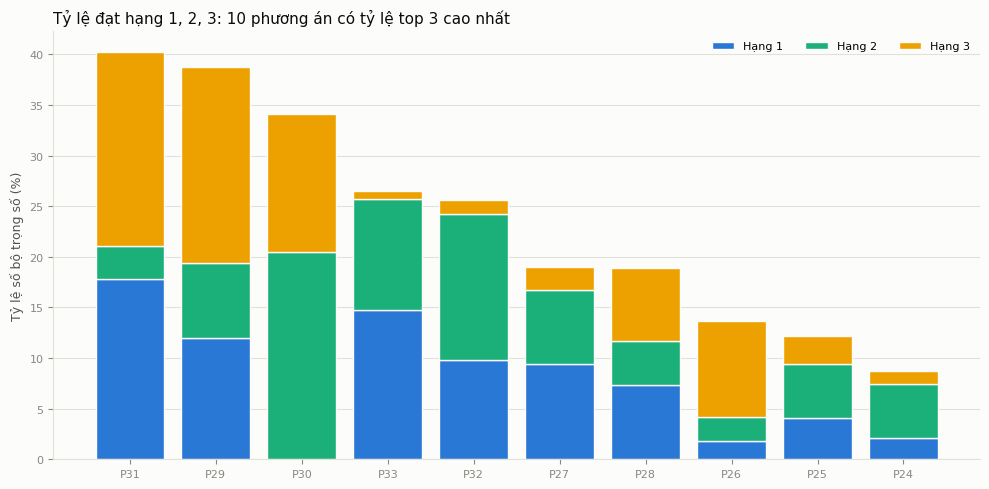

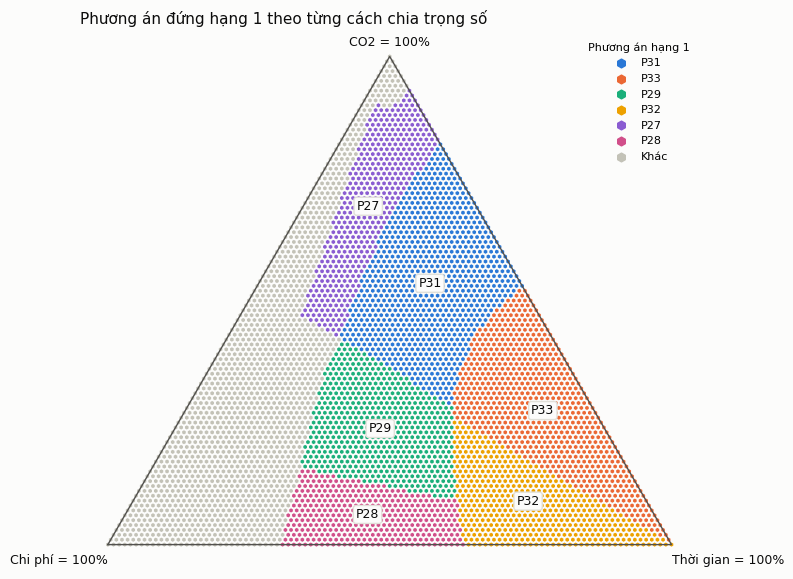

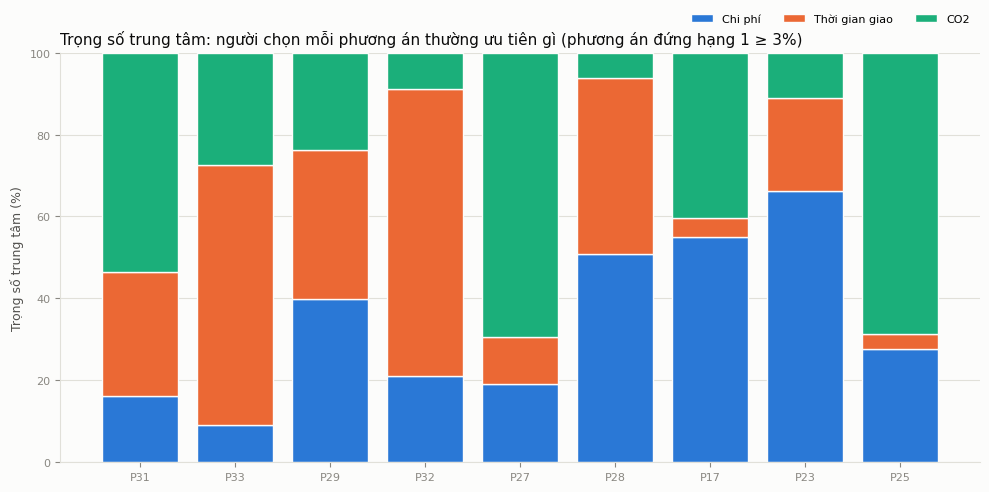

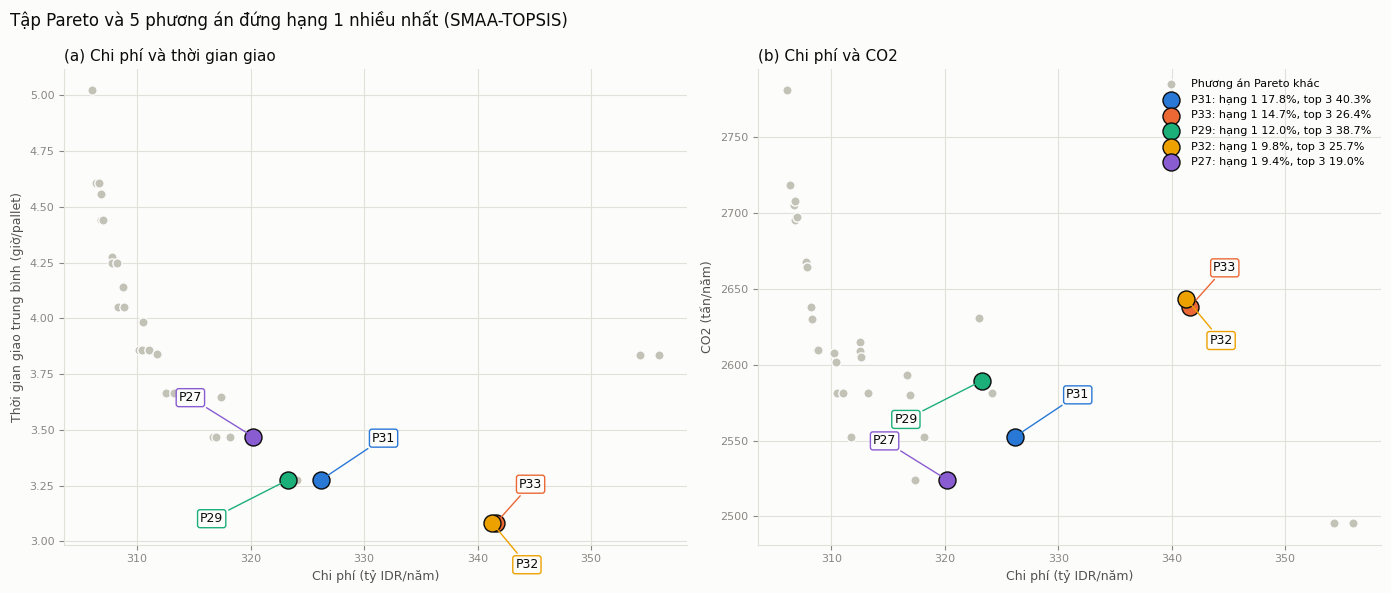

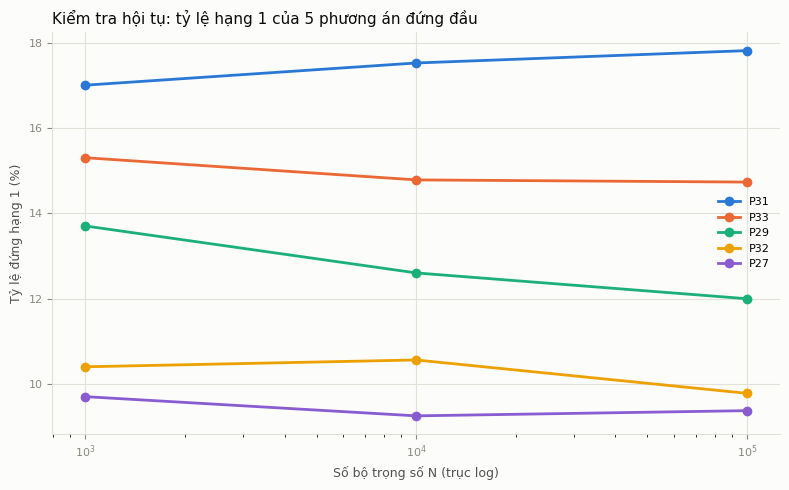

In [27]:
# ===== 3.3b HÌNH =====
import matplotlib.pyplot as plt
import shutil

# --- Màu và kiểu chung ---
NEN, CHU, PHU, MO, LUOI = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
XANH, LUC, VANG, CAM, XAM = "#2a78d6", "#1baf7a", "#eda100", "#eb6834", "#c3c2b7"
def kieu(ax, luoi="y"):
    ax.set_facecolor(NEN)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color(LUOI)
    ax.tick_params(colors=MO, labelsize=8)
    if luoi:
        ax.grid(True, axis=luoi, color=LUOI, linewidth=0.8)
        ax.set_axisbelow(True)

# --- (1) Cột chồng hạng 1/2/3 cho 10 phương án có Top3_% cao nhất ---
t = chap_nhan.sort_values("Top3_%", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(10, 5), facecolor=NEN)
day = np.zeros(len(t))
for cot, mau, nhan in [("Hang1_%", XANH, "Hạng 1"), ("Hang2_%", LUC, "Hạng 2"), ("Hang3_%", VANG, "Hạng 3")]:
    ax.bar(t["PhuongAn"], t[cot], bottom=day, color=mau, edgecolor=NEN, linewidth=1, label=nhan)
    day += t[cot].to_numpy()
ax.set_ylabel("Tỷ lệ số bộ trọng số (%)", color=PHU, fontsize=9)
ax.set_title("Tỷ lệ đạt hạng 1, 2, 3: 10 phương án có tỷ lệ top 3 cao nhất", loc="left", color=CHU, fontsize=11)
ax.legend(frameon=False, fontsize=8, ncol=3)
kieu(ax)
fig.tight_layout()
fig.savefig(FIG / "smaa_rank_acceptability.png", dpi=200, bbox_inches="tight", facecolor=NEN)
plt.show()

# --- (2) Bản đồ trọng số: lưới bước 1% trên tam giác, tô màu theo phương án hạng 1 ---
luoi = np.array([(a, b, 100 - a - b) for a in range(101) for b in range(101 - a)]) / 100   # 5,151 bộ trọng số
thang_luoi = PA[topsis(X, luoi).argmax(axis=1)]
NOI_BAT = list(chap_nhan["PhuongAn"].head(6))                            # 6 phương án thắng nhiều nhất
MAU_PA = dict(zip(NOI_BAT, [XANH, CAM, LUC, VANG, "#8a5cd1", "#d14f8a"]))
def toa_do(w):                                                           # (chi phí, thời gian, CO2) -> (x, y); đỉnh Chi phí (0,0), Thời gian (1,0), CO2 (0.5, 0.87)
    return w[:, 1] + 0.5 * w[:, 2], np.sqrt(3) / 2 * w[:, 2]
x, y = toa_do(luoi)
fig, ax = plt.subplots(figsize=(8, 7.2), facecolor=NEN)
ax.scatter(x, y, s=9, marker="h", c=[MAU_PA.get(p, XAM) for p in thang_luoi], linewidths=0)
ax.plot([0, 1, 0.5, 0], [0, 0, np.sqrt(3) / 2, 0], color=PHU, linewidth=1)
for (xx, yy), nhan, ha, dy in [((0, 0), "Chi phí = 100%", "right", -14), ((1, 0), "Thời gian = 100%", "left", -14),
                               ((0.5, np.sqrt(3) / 2), "CO2 = 100%", "center", 8)]:
    ax.annotate(nhan, (xx, yy), xytext=(0, dy), textcoords="offset points", ha=ha, color=CHU, fontsize=9)
for pa in NOI_BAT:                                                       # chú thích tại trọng số trung tâm
    w_tt = trung_tam.set_index("PhuongAn").loc[pa, ["W_ChiPhi_%", "W_ThoiGian_%", "W_CO2_%"]].to_numpy(float)[None, :] / 100
    cx, cy = toa_do(w_tt)
    ax.annotate(pa, (cx[0], cy[0]), ha="center", va="center", fontsize=9, color=CHU, bbox=dict(boxstyle="round,pad=0.2", fc=NEN, ec=LUOI))
for pa, mau in list(MAU_PA.items()) + [("Khác", XAM)]:
    ax.scatter([], [], s=40, marker="h", color=mau, label=pa)
ax.legend(frameon=False, fontsize=8, loc="upper right", title="Phương án hạng 1", title_fontsize=8)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Phương án đứng hạng 1 theo từng cách chia trọng số", loc="left", color=CHU, fontsize=11)
fig.savefig(FIG / "smaa_weight_map.png", dpi=200, bbox_inches="tight", facecolor=NEN)
plt.show()

# --- (3) Trọng số trung tâm (cột chồng 3 màu) cho phương án có Hang1_% >= 3% ---
chon = chap_nhan.loc[chap_nhan["Hang1_%"] >= 3, "PhuongAn"]
t = trung_tam.set_index("PhuongAn").loc[chon]
fig, ax = plt.subplots(figsize=(10, 5), facecolor=NEN)
day = np.zeros(len(t))
for cot, mau, nhan in [("W_ChiPhi_%", XANH, "Chi phí"), ("W_ThoiGian_%", CAM, "Thời gian giao"), ("W_CO2_%", LUC, "CO2")]:
    ax.bar(t.index, t[cot], bottom=day, color=mau, edgecolor=NEN, linewidth=1, label=nhan)
    day += t[cot].to_numpy()
ax.set_ylabel("Trọng số trung tâm (%)", color=PHU, fontsize=9)
ax.set_ylim(0, 100)
ax.set_title("Trọng số trung tâm: người chọn mỗi phương án thường ưu tiên gì (phương án đứng hạng 1 ≥ 3%)", loc="left", color=CHU, fontsize=11)
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper right", bbox_to_anchor=(1, 1.12))
kieu(ax)
fig.tight_layout()
fig.savefig(FIG / "smaa_central_weights.png", dpi=200, bbox_inches="tight", facecolor=NEN)
plt.show()

# --- (4) Tập Pareto: 2 khung (chi phí - thời gian giao, chi phí - CO2), tô màu riêng top 5 SMAA ---
MAU_TOP5 = dict(zip(TOP5, [XANH, CAM, LUC, VANG, "#8a5cd1"]))
LECH = [(45, 30), (25, 28), (-55, -28), (25, -30), (-45, 28)]            # vị trí nhãn so với điểm (điểm ảnh), tránh đè nhau
tt = chap_nhan.set_index("PhuongAn")
fig, axes = plt.subplots(1, 2, figsize=(14, 6), facecolor=NEN)
for ax, cot_y, ten_y in [(axes[0], "f2_gio", "Thời gian giao trung bình (giờ/pallet)"),
                         (axes[1], "f3", "CO2 (tấn/năm)")]:
    khac = pareto[~pareto["PhuongAn"].isin(TOP5)]
    ax.scatter(khac["f1"], khac[cot_y], s=45, color=XAM, edgecolors=NEN, linewidths=1, zorder=2, label="Phương án Pareto khác")
    for (pa, mau), (dx, dy) in zip(MAU_TOP5.items(), LECH):
        r = pareto[pareto["PhuongAn"] == pa].iloc[0]
        ax.scatter(r["f1"], r[cot_y], s=150, color=mau, edgecolors=CHU, linewidths=1, zorder=3,
                   label=f"{pa}: hạng 1 {tt.loc[pa, 'Hang1_%']:.1f}%, top 3 {tt.loc[pa, 'Top3_%']:.1f}%")
        ax.annotate(pa, (r["f1"], r[cot_y]), xytext=(dx, dy), textcoords="offset points", fontsize=9, color=CHU,
                    ha="center", va="center", bbox=dict(boxstyle="round,pad=0.2", fc=NEN, ec=mau),
                    arrowprops=dict(arrowstyle="-", color=mau, linewidth=1))
    ax.set_xlabel("Chi phí (tỷ IDR/năm)", color=PHU, fontsize=9)
    ax.set_ylabel(ten_y, color=PHU, fontsize=9)
    kieu(ax, luoi="both")
axes[0].set_title("(a) Chi phí và thời gian giao", loc="left", color=CHU, fontsize=11)
axes[1].set_title("(b) Chi phí và CO2", loc="left", color=CHU, fontsize=11)
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("Tập Pareto và 5 phương án đứng hạng 1 nhiều nhất (SMAA-TOPSIS)", x=0.01, ha="left", color=CHU, fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "smaa_pareto_highlight.png", dpi=200, bbox_inches="tight", facecolor=NEN)
plt.show()

# --- (5) Hội tụ: tỷ lệ hạng 1 của top 5 theo N (trục log) ---
fig, ax = plt.subplots(figsize=(8, 5), facecolor=NEN)
for pa, mau in zip(TOP5, [XANH, CAM, LUC, VANG, "#8a5cd1"]):
    t = hoi_tu[hoi_tu["PhuongAn"] == pa]
    ax.plot(t["N"], t["Hang1_%"], marker="o", color=mau, linewidth=2, label=pa)
ax.set_xscale("log")
ax.set_xlabel("Số bộ trọng số N (trục log)", color=PHU, fontsize=9)
ax.set_ylabel("Tỷ lệ đứng hạng 1 (%)", color=PHU, fontsize=9)
ax.set_title("Kiểm tra hội tụ: tỷ lệ hạng 1 của 5 phương án đứng đầu", loc="left", color=CHU, fontsize=11)
ax.legend(frameon=False, fontsize=8)
kieu(ax, luoi="both")
fig.tight_layout()
fig.savefig(FIG / "smaa_convergence.png", dpi=200, bbox_inches="tight", facecolor=NEN)
plt.show()

# --- Bản sao hình cho Mẹ ---
for hinh in ["smaa_rank_acceptability.png", "smaa_weight_map.png", "smaa_central_weights.png", "smaa_pareto_highlight.png", "smaa_convergence.png"]:
    shutil.copy2(FIG / hinh, MOM / hinh)

In [28]:
# ===== 3.3c KIỂM TRA FILE ĐÃ TẠO =====
for f in sorted(TOP.glob("smaa_*")):
    print(f.name, f"{f.stat().st_size / 1024:.0f} KB")
print()
print(pd.read_csv(TOP / "smaa_rank_acceptability.csv").head(10).round(2).to_string(index=False))

smaa_central_weights.csv 2 KB
smaa_central_weights.png 51 KB
smaa_convergence.csv 0 KB
smaa_convergence.png 76 KB
smaa_pareto_highlight.png 189 KB
smaa_rank_acceptability.csv 4 KB
smaa_rank_acceptability.png 48 KB
smaa_rank_acceptability_full.csv 11 KB
smaa_weight_map.png 414 KB

PhuongAn     f1  f2_gio      f3  SoKhoMo  Hang1_%  Hang2_%  Hang3_%  Top3_%
     P31 326.21    3.28 2552.65     51.0    17.81     3.29    19.16   40.26
     P33 341.62    3.08 2638.24     52.0    14.73    11.03     0.69   26.45
     P29 323.30    3.28 2589.57     49.0    12.00     7.41    19.33   38.74
     P32 341.29    3.08 2643.43     51.0     9.78    14.45     1.43   25.65
     P27 320.20    3.47 2524.12     50.0     9.37     7.31     2.30   18.97
     P28 323.01    3.28 2630.98     46.0     7.37     4.35     7.20   18.92
     P17 311.71    3.84 2552.65     45.0     5.28     1.10     2.12    8.50
     P23 316.70    3.47 2593.09     45.0     4.47     1.64     1.64    7.75
     P25 317.38    3.65 2524.12    

## 3.4 Tóm tắt

Kết quả lần chạy 18/10: 35 phương án Pareto, 100,000 bộ trọng số, seed 42.

**Phương án hay đứng hạng 1 nhất**

| Phương án | Hạng 1 | Top 3 | Chi phí (tỷ IDR) | Giao (giờ) | CO2 (tấn) | Số kho mở |
|---|---|---|---|---|---|---|
| P31 | 17.7% | 40.3% | 326.21 | 3.28 | 2,553 | 51 |
| P33 | 14.8% | 26.7% | 341.62 | 3.08 | 2,638 | 52 |
| P29 | 11.8% | 38.6% | 323.30 | 3.28 | 2,590 | 49 |

- Không phương án nào thắng áp đảo. Phương án đứng đầu chỉ đứng hạng 1 trong khoảng 1/6 số bộ trọng số.
- Xét theo tỷ lệ lọt top 3, ba phương án đứng đầu là P31 (40.3%), P29 (38.6%) và P30 (33.8%). P30 gần như không bao giờ đứng hạng 1 (0.01%) nhưng rất hay đứng hạng 2 hoặc 3. Đây là phương án "luôn ở gần đầu, không bao giờ nhất".

**Người chọn mỗi phương án thường ưu tiên gì (trọng số trung tâm: chi phí / thời gian giao / CO2)**

- P31: 16 / 30 / 54%. Người coi trọng CO2 nhất.
- P33: 9 / 63 / 28%. Người coi trọng giao nhanh nhất.
- P29: 40 / 36 / 24%. Người chia đều giữa chi phí và giao nhanh.
- P32: 21 / 70 / 9%. Người rất coi trọng giao nhanh, ít quan tâm CO2.
- P27: 19 / 12 / 70%. Người rất coi trọng CO2.
- P28: 51 / 43 / 6%. Người coi trọng chi phí và giao nhanh, gần như bỏ qua CO2.
- P17, P23: chi phí 55–66%. Người coi trọng chi phí nhất.

**Phương án gần như không bao giờ thắng**

- 6 phương án không lần nào đứng hạng 1: P03, P07, P08, P09, P16, P35.
- 14 phương án đứng hạng 1 dưới 1% số lần. Trong đó có P01 (phương án rẻ nhất, 0.01%) và P34 (0.78%).
- Hai phương án ở hai đầu tập Pareto đều gần như không thắng. P01 rẻ nhất nhưng giao chậm nhất và nhiều CO2 nhất. P35 ít CO2 nhất nhưng đắt nhất. TOPSIS ưa phương án cân bằng hơn phương án cực đoan.

**Độ ổn định**

Tỷ lệ hạng 1 của top 5 ở N = 10,000 và N = 100,000 lệch nhau dưới 0.7 điểm %. Thứ tự P31 > P33 > P29 > P32 > P27 giữ nguyên.